# Lab: Logistic Regression

## Formula

### Model
$$
g(z) = \frac{1}{1 + e^{-(z)}}
$$
where,
$$
z = f_{\vec{w}, b} (\vec{X}) = \vec{X} \cdot \vec{w} + b
$$

### Cost Function
$$
J(\vec{w}, b) =  \sum_{i=1}^{m} \frac{1}{m} -y^{(i)} log(f_{\vec{w}, b}(X^{(i)})) - (1 - y^{(i)}) log(1 - f_{\vec{w}, b}(X^{(i)}))
$$

## Gradient Descent
$$
\begin{aligned}
& \text{repeat until convergence } \{ \\
& w = w - \alpha \frac{1}{m}\sum_{i=1}^{m} (f_{w,b}(x^{(i)}) - y^{(i)}) x^{(i)} \\
& b = b - \alpha \frac{1}{m}\sum_{i=1}^{m} (f_{w,b}(x^{(i)}) - y^{(i)}) \\
& \}
\end{aligned}
$$

In [8]:
import numpy as np
 
 
class LogisticRegression:
    def __init__(self, n_iter=10000, convergence_limit=1e-7, learning_rate=0.1):
        self.n_iter = n_iter
        self.convergence_limit = convergence_limit
        self.learning_rate = learning_rate
 
    def logistic_model(self, z):
        z = np.clip(z, -500, 500)  # keeps np.exp from overflowing on extreme values
        return 1 / (1 + np.exp(-z))
 
    def linear_regression_model(self, X):
        return np.dot(X, self.weights) + self.bias
 
    def _model(self, X):
        # Logistic regression = sigmoid applied to the linear model
        return self.logistic_model(self.linear_regression_model(X))
 
    def _cost_function(self):
        f_wb = self._model(self.X)
        f_wb = np.clip(f_wb, 1e-15, 1 - 1e-15)  # avoids log(0)
 
        J_wb = -np.mean(self.y * np.log(f_wb) + (1 - self.y) * np.log(1 - f_wb))
        return J_wb
 
    def _gradient(self):
        dL_df = self._model(self.X) - self.y  # error for every row at once, shape (m,)
 
        dL_dw = np.dot(self.X.T, dL_df) / self.m  # sums dL_df[i] * X[i] over all rows
        dL_db = np.mean(dL_df)
 
        return dL_dw, dL_db
 
    def _gradient_descent(self):
        for i in range(self.n_iter):
            dL_dw, dL_db = self._gradient()
 
            w_temp = self.weights - self.learning_rate * dL_dw
            b_temp = self.bias - self.learning_rate * dL_db
 
            self.weights = w_temp
            self.bias = b_temp
 
            self.history.append(self._cost_function())
 
            converged = len(self.history) > 1 and abs(self.history[-1] - self.history[-2]) < self.convergence_limit
            diverged = not np.isfinite(self.history[-1])
 
            if converged or diverged:
                break
 
        return self
 
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()  # a column-vector y would otherwise broadcast to (m, m)
 
        if X.ndim == 1:
            X = X.reshape(-1, 1)
 
        # Feature Scaling "z-score"
        self.mean = np.mean(X, axis=0)
 
        self.std = np.std(X, axis=0)
        self.std[self.std == 0] = 1.0
 
        self.X = (X - self.mean) / self.std
        self.y = y
 
        self.m = self.X.shape[0]  # Number of Data Rows
        self.n = self.X.shape[1]  # Number of Features
 
        self.weights = np.zeros(self.n)
        self.bias = 0.0
 
        self.history = []
 
        # Finding best parameters
        self._gradient_descent()
 
        return self
 
    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim < 2:
            X = X.reshape(-1, self.n)  # one sample, or a 1-D array of single-feature samples
 
        # Feature Rescaling (for test data), using the training mean/std
        X = (X - self.mean) / self.std
 
        return self._model(X)  # probability that y = 1
 
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

In [9]:
# Test Data
# P(y = 1) = sigmoid(1.2*x1 - 0.8*x2 + 1.0), 100 samples
# x1, x2 drawn uniformly from [-5, 5]; each label is 1 with probability P(y = 1), otherwise 0

X = np.array([
    [  2.74,  -0.61],
    [  3.59,   1.97],
    [ -4.06,   4.76],
    [  2.61,   2.86],
    [ -3.72,  -0.50],
    [ -1.29,   4.27],
    [  1.44,   3.23],
    [ -0.57,  -2.73],
    [  0.55,  -4.36],
    [  3.28,   1.32],
    [  2.58,  -1.45],
    [  4.71,   3.93],
    [  2.78,  -3.05],
    [ -0.33,  -4.56],
    [ -3.46,   1.83],
    [  2.45,   4.68],
    [ -1.74,  -1.30],
    [ -0.30,  -3.11],
    [ -3.70,  -0.24],
    [ -2.73,   1.70],
    [ -0.63,   3.33],
    [  2.00,  -1.88],
    [  3.32,   3.05],
    [ -1.13,  -2.12],
    [  1.82,  -3.60],
    [ -3.00,  -4.93],
    [  2.87,   1.65],
    [  2.05,   2.81],
    [ -0.41,   0.69],
    [ -3.60,  -3.85],
    [  1.68,  -0.29],
    [  0.65,   2.65],
    [  1.35,   0.54],
    [  0.59,  -1.96],
    [ -4.69,  -0.63],
    [ -2.85,  -0.91],
    [  3.53,  -2.66],
    [ -4.42,  -2.19],
    [ -2.06,   1.62],
    [  0.57,   2.84],
    [  1.64,  -0.94],
    [  3.14,  -3.33],
    [ -4.77,  -4.10],
    [  2.22,  -0.38],
    [ -3.39,   0.01],
    [ -3.48,   1.96],
    [ -0.54,  -1.19],
    [ -1.98,   1.30],
    [ -1.38,  -4.12],
    [ -3.82,   4.62],
    [  4.09,   2.00],
    [ -2.34,   4.69],
    [  2.79,   2.17],
    [ -0.51,  -2.28],
    [ -4.04,   4.03],
    [ -0.44,  -2.98],
    [ -1.94,   0.79],
    [ -3.23,   3.57],
    [  2.59,   2.19],
    [ -0.68,   1.27],
    [  0.84,   1.50],
    [ -4.16,  -0.84],
    [ -4.58,  -0.06],
    [ -1.70,  -3.55],
    [ -3.97,   0.88],
    [ -3.29,   4.25],
    [  0.81,  -1.53],
    [  0.91,  -4.77],
    [  4.59,  -0.18],
    [  2.83,  -4.17],
    [ -0.13,  -0.09],
    [  4.38,   0.72],
    [ -0.27,  -2.33],
    [ -1.68,   0.21],
    [ -0.61,  -4.78],
    [  3.26,   3.96],
    [ -3.60,   0.54],
    [ -3.91,   1.72],
    [ -2.19,   1.59],
    [  2.27,   2.69],
    [ -3.92,   4.16],
    [ -2.70,  -4.63],
    [  0.55,  -1.29],
    [  3.30,   3.08],
    [ -1.83,   4.53],
    [ -2.09,   0.15],
    [ -2.44,   4.36],
    [ -3.35,  -4.55],
    [ -0.65,   4.92],
    [  3.92,   2.49],
    [  3.91,   3.93],
    [  0.19,  -1.84],
    [  2.72,   1.62],
    [ -1.26,  -4.06],
    [  2.47,  -2.38],
    [  4.37,  -2.59],
    [ -3.77,   3.31],
    [ -3.47,  -3.21],
    [  0.99,   3.75],
    [ -3.04,  -1.90],
])

y = np.array([
    1, 1, 0, 1, 1, 0, 1, 1, 1, 1,
    1, 1, 1, 1, 0, 0, 1, 1, 0, 0,
    0, 1, 1, 0, 1, 0, 1, 1, 0, 1,
    1, 0, 0, 1, 0, 0, 1, 0, 1, 1,
    1, 1, 0, 1, 0, 0, 1, 0, 1, 0,
    1, 0, 1, 1, 0, 1, 0, 0, 1, 0,
    1, 0, 0, 1, 0, 0, 1, 1, 1, 1,
    1, 1, 1, 0, 1, 1, 0, 0, 0, 0,
    0, 1, 1, 1, 0, 0, 0, 1, 0, 1,
    1, 1, 1, 1, 1, 1, 0, 0, 0, 0,
])

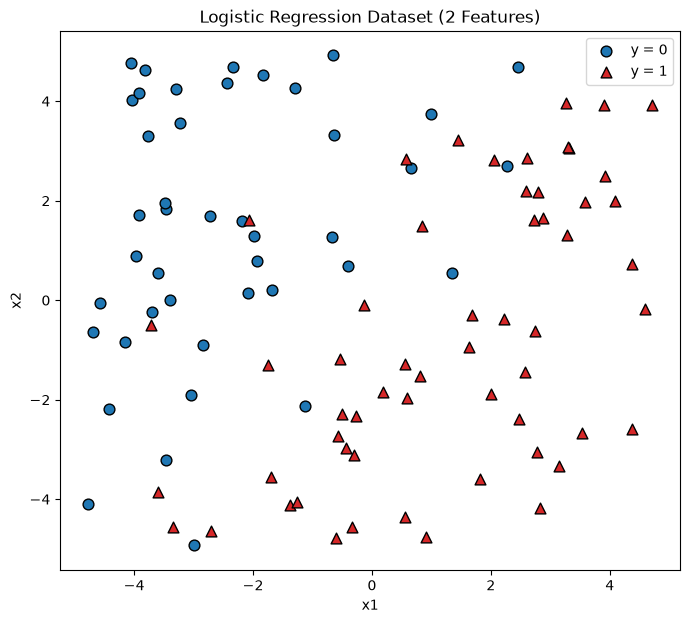

In [10]:
import matplotlib.pyplot as plt

# Extract features
x1 = X[:, 0]
x2 = X[:, 1]

# Create 2D plot (y is a 0/1 label, so color the points by class instead of using a third axis)
fig, ax = plt.subplots(figsize=(8, 7))

# Plot data points
ax.scatter(x1[y == 0], x2[y == 0], color="tab:blue", edgecolors="black", s=60, label="y = 0")
ax.scatter(x1[y == 1], x2[y == 1], color="tab:red", marker="^", edgecolors="black", s=60, label="y = 1")

# Labels
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("Logistic Regression Dataset (2 Features)")

ax.legend()
plt.show()

In [11]:
# Four different Logistic Regression models with learning rate change
lr1 = LogisticRegression(n_iter=10000, convergence_limit=1e-7, learning_rate=0.1)
lr2 = LogisticRegression(n_iter=10000, convergence_limit=1e-7, learning_rate=0.01)
lr3 = LogisticRegression(n_iter=10000, convergence_limit=1e-7, learning_rate=0.001)
lr4 = LogisticRegression(n_iter=10000, convergence_limit=1e-7, learning_rate=0)

lr1.fit(X, y)
lr2.fit(X, y)
lr3.fit(X, y)
lr4.fit(X, y)

models = [lr1, lr2, lr3, lr4]
names = ["LR1", "LR2", "LR3", "LR4"]

# 10000 means the model hit n_iter before converging
# LR4 stops after 2 iterations: with α = 0 the cost never changes, so the convergence check fires
for name, model in zip(names, models):
    print(f"{name}: stopped after {len(model.history)} iterations")

LR1: stopped after 1948 iterations
LR2: stopped after 10000 iterations
LR3: stopped after 10000 iterations
LR4: stopped after 2 iterations


In [12]:
# Predictions at [2.0, 3.0] --> P(y = 1) = sigmoid(1.2*2.0 - 0.8*3.0 + 1.0) = sigmoid(1.0) = 0.73, class 1
# (a fully converged model gets about 0.71 on this sample; the small gap is sampling noise)
# LR4 never moves away from w = 0, b = 0, so it predicts 0.5 for every input

for name, model in zip(names, models):
    p = model.predict_proba([2.0, 3.0])[0]
    c = model.predict([2.0, 3.0])[0]
    print(f"{name}: P(y = 1) = {p:.3f}, class = {c}")

LR1: P(y = 1) = 0.714, class = 1
LR2: P(y = 1) = 0.711, class = 1
LR3: P(y = 1) = 0.651, class = 1
LR4: P(y = 1) = 0.500, class = 1


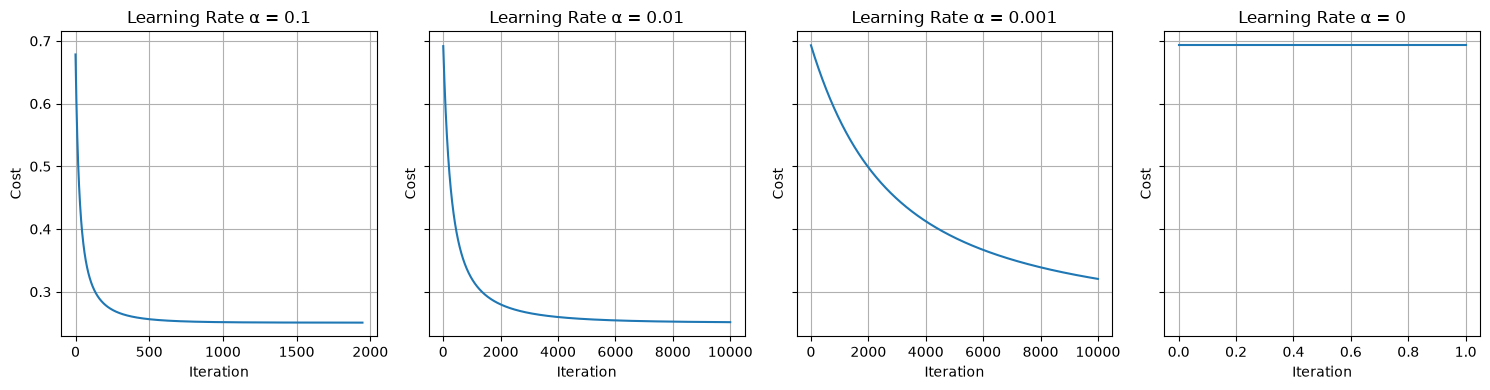

In [13]:
# Cost Function - Loss every iteration
# Every model starts near ln(2) ≈ 0.693, the cost when w = 0 and b = 0 (every prediction is 0.5)
# A fully converged model ends around 0.25 on this data
import matplotlib.pyplot as plt

histories = [lr1.history, lr2.history, lr3.history, lr4.history]
alphas = [0.1, 0.01, 0.001, 0]

# sharey=True puts all four plots on the same cost scale so they are easy to compare
fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharey=True)

for i, (history, alpha) in enumerate(zip(histories, alphas)):
    axes[i].plot(history)
    axes[i].set_title(f"Learning Rate α = {alpha}")
    axes[i].set_xlabel("Iteration")
    axes[i].set_ylabel("Cost")
    axes[i].grid(True)

plt.tight_layout()
plt.show()

In [14]:
# Accuracy and learned parameters, converted back from z-scored features to the original x1, x2 scale
# True: w1 = 1.2, w2 = -0.8, b = 1.0
# A fully converged model gets about w1 = 1.16, w2 = -0.80, b = 0.99 and accuracy 0.91 on this sample
# (even the true model only scores 0.90 here, because labels near the boundary are random)
# LR4 predicts class 1 for everything (P = 0.5 counts as class 1), so its accuracy is just the share of 1s

for name, model in zip(names, models):
    accuracy = np.mean(model.predict(X) == y)
    w = model.weights / model.std
    b = model.bias - np.sum(model.weights * model.mean / model.std)
    print(f"{name}: accuracy = {accuracy:.2f}, w1 = {w[0]:.2f}, w2 = {w[1]:.2f}, b = {b:.2f}")

LR1: accuracy = 0.91, w1 = 1.14, w2 = -0.78, b = 0.97
LR2: accuracy = 0.91, w1 = 1.08, w2 = -0.73, b = 0.93
LR3: accuracy = 0.89, w1 = 0.53, w2 = -0.32, b = 0.52
LR4: accuracy = 0.57, w1 = 0.00, w2 = 0.00, b = 0.00


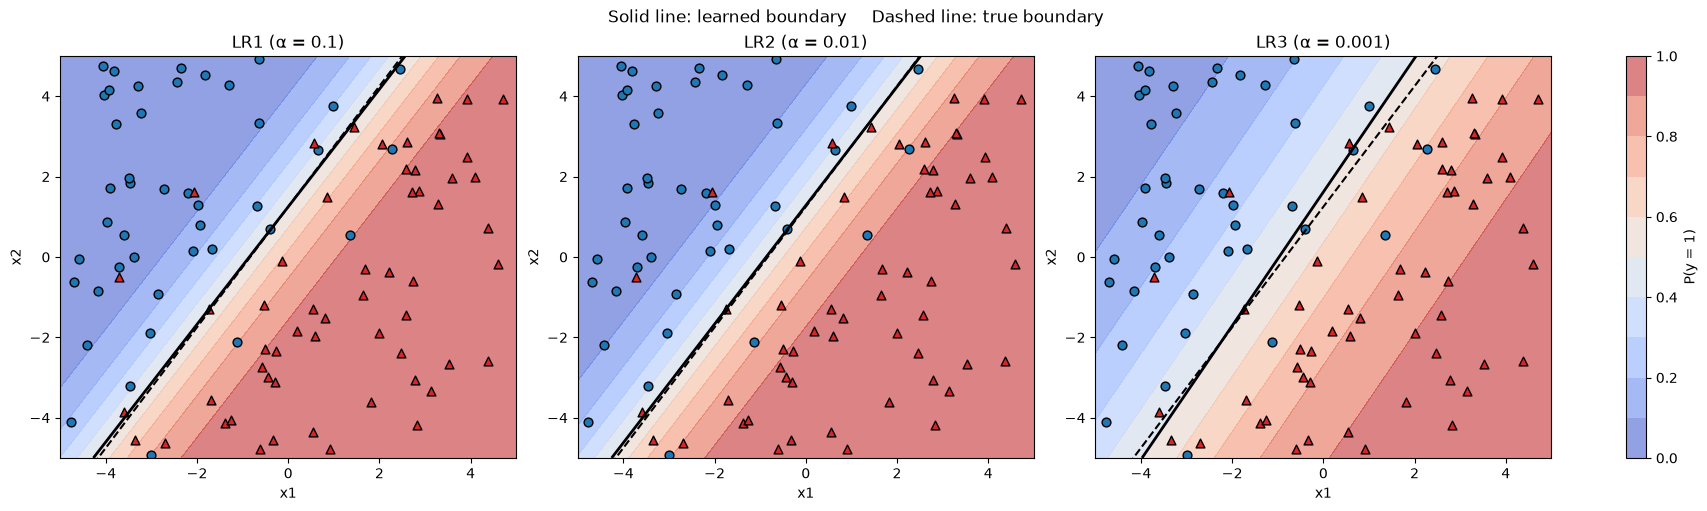

In [15]:
# Decision Boundary - background is each model's P(y = 1), solid line is where P(y = 1) = 0.5
# Dashed line is the true boundary: 1.2*x1 - 0.8*x2 + 1.0 = 0  -->  x2 = 1.5*x1 + 1.25
# LR4 is left out because its P(y = 1) is 0.5 everywhere, so it has no boundary
import matplotlib.pyplot as plt

g1, g2 = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-5, 5, 200))
grid = np.column_stack([g1.ravel(), g2.ravel()])
line_x1 = np.linspace(-5, 5, 100)

fig, axes = plt.subplots(1, 3, figsize=(17, 5), layout="constrained")

for ax, name, model, alpha in zip(axes, names, models, alphas):
    P = model.predict_proba(grid).reshape(g1.shape)
    background = ax.contourf(g1, g2, P, levels=np.linspace(0, 1, 11), cmap="coolwarm", alpha=0.6)
    ax.contour(g1, g2, P, levels=[0.5], colors="black", linewidths=2)
    ax.plot(line_x1, 1.5 * line_x1 + 1.25, "k--", linewidth=1.5)

    ax.scatter(x1[y == 0], x2[y == 0], color="tab:blue", edgecolors="black", s=40)
    ax.scatter(x1[y == 1], x2[y == 1], color="tab:red", marker="^", edgecolors="black", s=40)

    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(f"{name} (α = {alpha})")

fig.colorbar(background, ax=axes, label="P(y = 1)")
fig.suptitle("Solid line: learned boundary     Dashed line: true boundary")
plt.show()